In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

# Plot style
sns.set_style("whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:


np.random.seed(42)

n_samples = 1000

data = {
    'Debt_to_Income_Ratio': np.random.uniform(0.1, 0.8, n_samples),
    'Credit_Score': np.random.randint(300, 850, n_samples),
    'Annual_Income': np.random.uniform(20000, 150000, n_samples),
    'Missed_Payments_Count': np.random.randint(0, 10, n_samples)
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)


Dataset created successfully!

First 5 rows:


,Debt_to_Income_Ratio,Credit_Score,Annual_Income,Missed_Payments_Count
0,0.362178,311,97917.965536,1
1,0.765500,617,98278.933727,8
2,0.612396,515,22981.265465,0
3,0.519061,638,61874.040550,9
4,0.209213,380,102743.784636,5



Dataset shape: (1000, 4)


In [ ]:


risk_index = (
    (df['Debt_to_Income_Ratio'] * 2.5)
    + (df['Missed_Payments_Count'] * 0.4)
    - (df['Credit_Score'] / 300.0)
)

df['Credit_Risk_Rating'] = pd.qcut(
    risk_index,
    q=3,
    labels=[0, 1, 2]
).astype(int)

print("Target variable created successfully!")

print("\nRisk class distribution:")
print(df['Credit_Risk_Rating'].value_counts().sort_index())


Target variable created successfully!

Risk class distribution:
Credit_Risk_Rating
0    333
1    334
2    333
Name: count, dtype: int64


In [ ]:


X = df[
    [
        'Debt_to_Income_Ratio',
        'Credit_Score',
        'Annual_Income',
        'Missed_Payments_Count'
    ]
]

y = df['Credit_Risk_Rating']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Credit_Risk_Rating")


Features:
['Debt_to_Income_Ratio', 'Credit_Score', 'Annual_Income', 'Missed_Payments_Count']

Target:
Credit_Risk_Rating


In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 800
Testing samples: 200


In [ ]:


dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")
print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())


Decision Tree trained successfully!
Tree depth: 4
Number of leaves: 16


In [ ]:


y_pred = dt_model.predict(X_test)

# Probability predictions
y_prob = dt_model.predict_proba(X_test)

print("First 10 actual values:")
print(y_test.values[:10])

print("\nFirst 10 predicted values:")
print(y_pred[:10])


First 10 actual values:
[0 2 1 1 2 1 2 0 0 0]

First 10 predicted values:
[0 2 1 2 2 1 2 0 0 0]


In [ ]:


accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print("========== MODEL PERFORMANCE ==========")

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))


========== MODEL PERFORMANCE ==========
Accuracy  : 0.84
Precision : 0.8456
Recall    : 0.84
F1-Score  : 0.8415


In [ ]:


print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Low Risk',
            'Moderate Risk',
            'High Risk'
        ]
    )
)


========== CLASSIFICATION REPORT ==========
               precision    recall  f1-score   support

     Low Risk       0.84      0.88      0.86        67
Moderate Risk       0.75      0.79      0.77        67
    High Risk       0.95      0.85      0.90        66

     accuracy                           0.84       200
    macro avg       0.85      0.84      0.84       200
 weighted avg       0.85      0.84      0.84       200



In [ ]:


cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[59  8  0]
 [11 53  3]
 [ 0 10 56]]


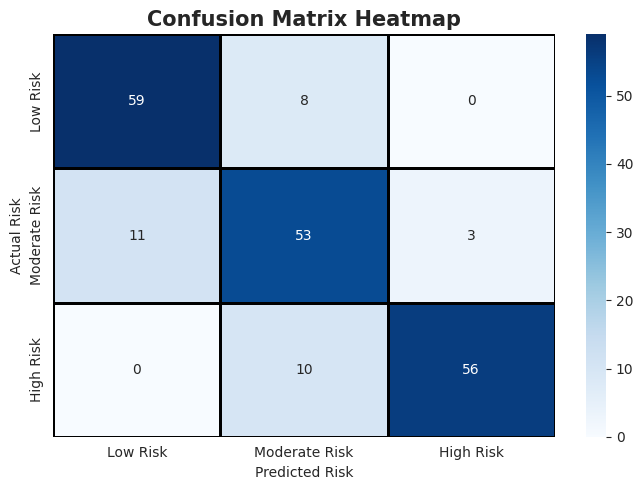

In [ ]:


plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='black',
    xticklabels=[
        'Low Risk',
        'Moderate Risk',
        'High Risk'
    ],
    yticklabels=[
        'Low Risk',
        'Moderate Risk',
        'High Risk'
    ]
)

plt.title(
    'Confusion Matrix Heatmap',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')

plt.tight_layout()
plt.show()


In [ ]:


feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("========== FEATURE IMPORTANCE ==========")
print(feature_importance)


========== FEATURE IMPORTANCE ==========
                 Feature  Importance
3  Missed_Payments_Count    0.566710
0   Debt_to_Income_Ratio    0.229803
1           Credit_Score    0.203488
2          Annual_Income    0.000000


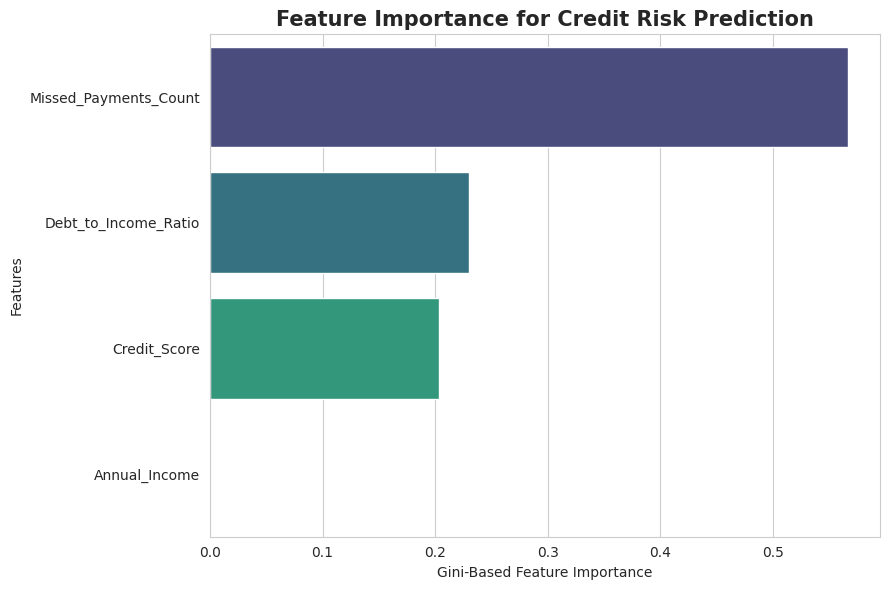

In [ ]:


plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title(
    'Feature Importance for Credit Risk Prediction',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Gini-Based Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()


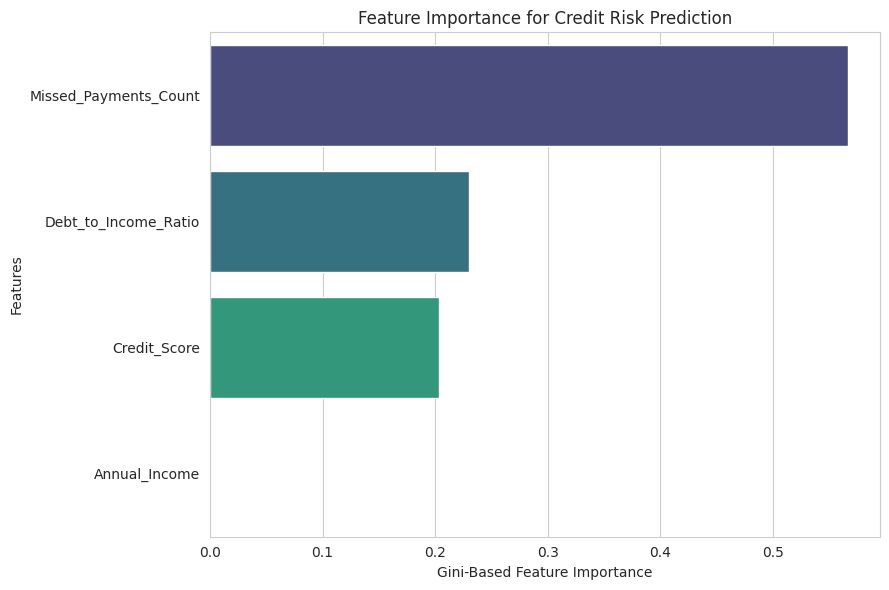

In [ ]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Feature Importance for Credit Risk Prediction')
plt.xlabel('Gini-Based Feature Importance')
plt.ylabel('Features')

plt.tight_layout()

plt.savefig(
    'feature_importance_bar_chart.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


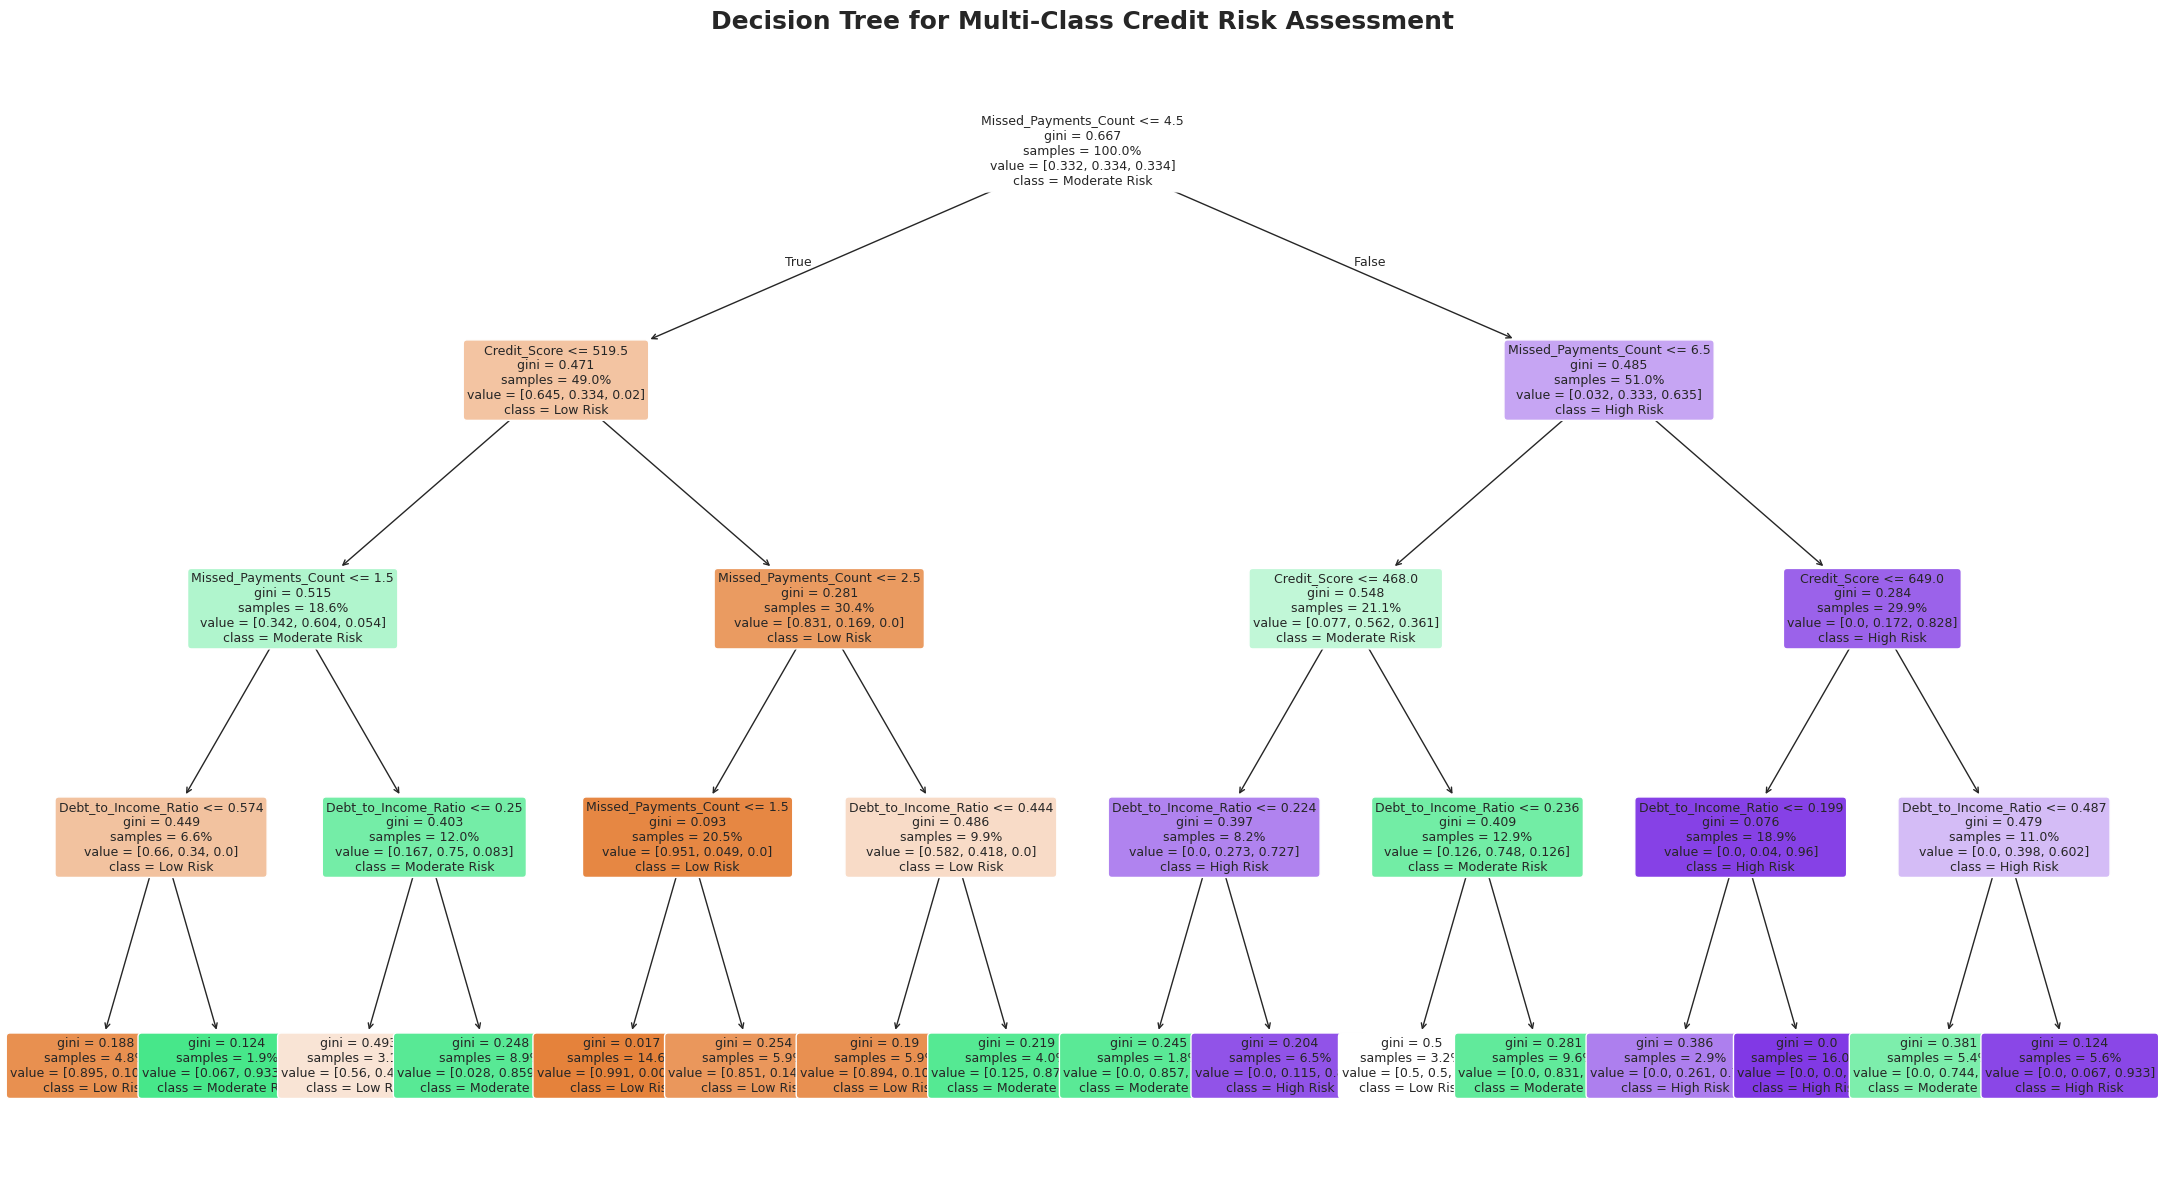

In [ ]:


plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[
        'Low Risk',
        'Moderate Risk',
        'High Risk'
    ],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=True,
    fontsize=9
)

plt.title(
    'Decision Tree for Multi-Class Credit Risk Assessment',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


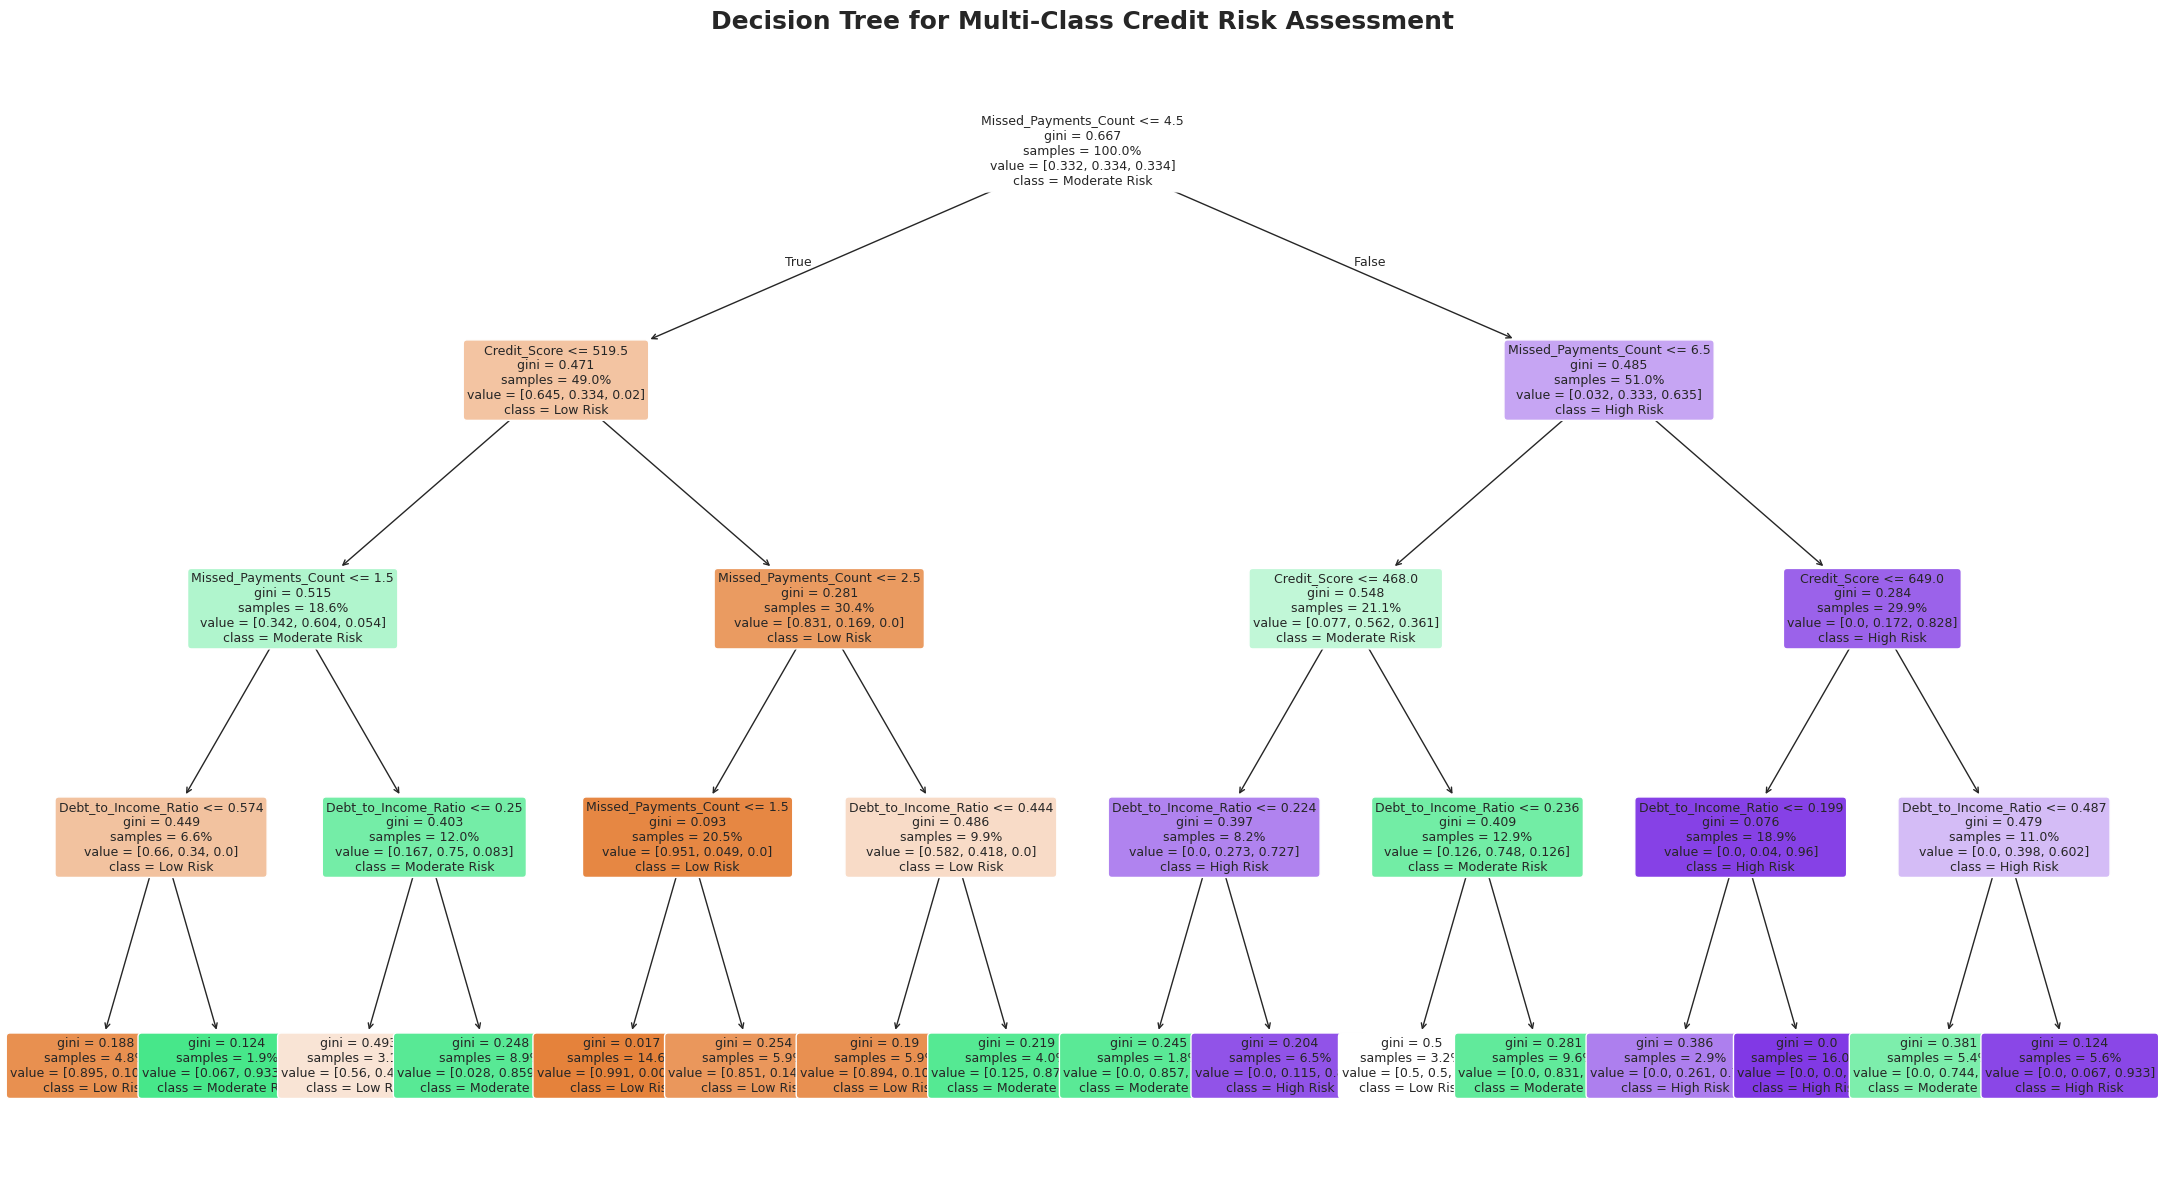

In [ ]:


plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[
        'Low Risk',
        'Moderate Risk',
        'High Risk'
    ],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=True,
    fontsize=9
)

plt.title(
    'Decision Tree for Multi-Class Credit Risk Assessment',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'decision_tree_diagram.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [ ]:


tree_rules = export_text(
    dt_model,
    feature_names=list(X.columns)
)

print("========== DECISION TREE RULES ==========")
print(tree_rules)


========== DECISION TREE RULES ==========
|--- Missed_Payments_Count <= 4.50
|   |--- Credit_Score <= 519.50
|   |   |--- Missed_Payments_Count <= 1.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.57
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.57
|   |   |   |   |--- class: 1
|   |   |--- Missed_Payments_Count >  1.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.25
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.25
|   |   |   |   |--- class: 1
|   |--- Credit_Score >  519.50
|   |   |--- Missed_Payments_Count <= 2.50
|   |   |   |--- Missed_Payments_Count <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- Missed_Payments_Count >  1.50
|   |   |   |   |--- class: 0
|   |   |--- Missed_Payments_Count >  2.50
|   |   |   |--- Debt_to_Income_Ratio <= 0.44
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.44
|   |   |   |   |--- class: 1
|--- Missed_Payments_Count >  4.50
|   |--- Missed_Payments_Count <= 6.50
|  

In [ ]:


path = dt_model.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas

print("Possible ccp_alpha values:")
print(ccp_alphas)


Possible ccp_alpha values:
[0.         0.00165214 0.00331702 0.00943119 0.01089108 0.01517233
 0.01816278 0.02152361 0.02313058 0.0303034  0.04665662 0.04981765
 0.18840482]


In [ ]:

# Select a small alpha value
alpha = ccp_alphas[-2] if len(ccp_alphas) > 1 else 0.0

pruned_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    ccp_alpha=alpha,
    random_state=42
)

pruned_tree.fit(X_train, y_train)

pruned_pred = pruned_tree.predict(X_test)

print("Pruned Tree Accuracy:",
      round(accuracy_score(y_test, pruned_pred), 4))

print("Pruned Tree Depth:",
      pruned_tree.get_depth())

print("Pruned Tree Leaves:",
      pruned_tree.get_n_leaves())


Pruned Tree Accuracy: 0.64
Pruned Tree Depth: 1
Pruned Tree Leaves: 2


In [ ]:


roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class='ovr',
    average='weighted'
)

print("Multi-Class ROC-AUC (OvR):", round(roc_auc, 4))


Multi-Class ROC-AUC (OvR): 0.9406


In [ ]:

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC (OvR)'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results['Score'] = results['Score'].round(4)

print("========== FINAL MODEL PERFORMANCE ==========")
display(results)


========== FINAL MODEL PERFORMANCE ==========


,Metric,Score
0,Accuracy,0.8400
1,Precision,0.8456
2,Recall,0.8400
3,F1-Score,0.8415
4,ROC-AUC (OvR),0.9406
